In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

X = np.linspace(-3, 3, 200).reshape(-1, 1)

y = 2 + 3 * X.ravel() + 2 * X.ravel()**2 + np.random.normal(0, 2, 200)

df = pd.DataFrame({
    'X': X.ravel(),
    'y': y
})

print(df.head())
print("\nDataset shape:", df.shape)

          X          y
0 -3.000000  11.993428
1 -2.969849  10.453933
2 -2.939698  11.759936
3 -2.909548  13.248353
4 -2.879397   9.475356

Dataset shape: (200, 2)


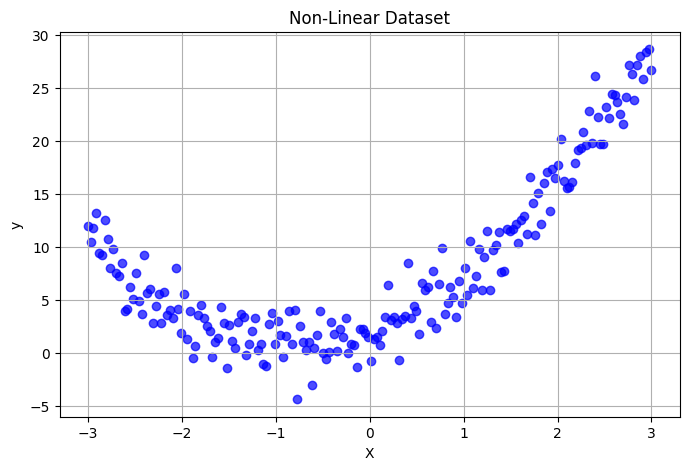

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7)
plt.title('Non-Linear Dataset')
plt.xlabel('X')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [5]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MSE:", mse_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

Linear Regression Results
MSE: 22.50227941402513
RMSE: 4.743656755502566
R2 Score: 0.5149562658101459


In [6]:
poly2_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly2_model.fit(X_train, y_train)

y_pred_poly2 = poly2_model.predict(X_test)

mse_poly2 = mean_squared_error(y_test, y_pred_poly2)
rmse_poly2 = np.sqrt(mse_poly2)
r2_poly2 = r2_score(y_test, y_pred_poly2)

print("Polynomial Regression Degree 2")
print("MSE:", mse_poly2)
print("RMSE:", rmse_poly2)
print("R2 Score:", r2_poly2)

Polynomial Regression Degree 2
MSE: 3.099239506473264
RMSE: 1.7604657072698873
R2 Score: 0.9331949143591398


In [7]:
poly10_model = make_pipeline(
    PolynomialFeatures(degree=10),
    StandardScaler(),
    LinearRegression()
)

poly10_model.fit(X_train, y_train)

y_pred_poly10 = poly10_model.predict(X_test)

mse_poly10 = mean_squared_error(y_test, y_pred_poly10)
rmse_poly10 = np.sqrt(mse_poly10)
r2_poly10 = r2_score(y_test, y_pred_poly10)

print("Polynomial Regression Degree 10")
print("MSE:", mse_poly10)
print("RMSE:", rmse_poly10)
print("R2 Score:", r2_poly10)

Polynomial Regression Degree 10
MSE: 3.1992260835136603
RMSE: 1.7886380526852437
R2 Score: 0.9310396721365983


In [8]:
ridge_model = make_pipeline(
    PolynomialFeatures(degree=10),
    StandardScaler(),
    Ridge(alpha=10)
)

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("MSE:", mse_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)

Ridge Regression Results
MSE: 3.2938224311734947
RMSE: 1.8148890961084907
R2 Score: 0.9290006180094394


In [9]:
lasso_model = make_pipeline(
    PolynomialFeatures(degree=10),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Results")
print("MSE:", mse_lasso)
print("RMSE:", rmse_lasso)
print("R2 Score:", r2_lasso)


Lasso Regression Results
MSE: 3.066537026382886
RMSE: 1.7511530562411972
R2 Score: 0.9338998266379563


In [10]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression Degree 2',
        'Polynomial Regression Degree 10',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'MSE': [
        mse_linear,
        mse_poly2,
        mse_poly10,
        mse_ridge,
        mse_lasso
    ],
    'RMSE': [
        rmse_linear,
        rmse_poly2,
        rmse_poly10,
        rmse_ridge,
        rmse_lasso
    ],
    'R2 Score': [
        r2_linear,
        r2_poly2,
        r2_poly10,
        r2_ridge,
        r2_lasso
    ]
})

print(results.round(4).to_string(index=False))


                          Model     MSE   RMSE  R2 Score
              Linear Regression 22.5023 4.7437    0.5150
 Polynomial Regression Degree 2  3.0992 1.7605    0.9332
Polynomial Regression Degree 10  3.1992 1.7886    0.9310
               Ridge Regression  3.2938 1.8149    0.9290
               Lasso Regression  3.0665 1.7512    0.9339


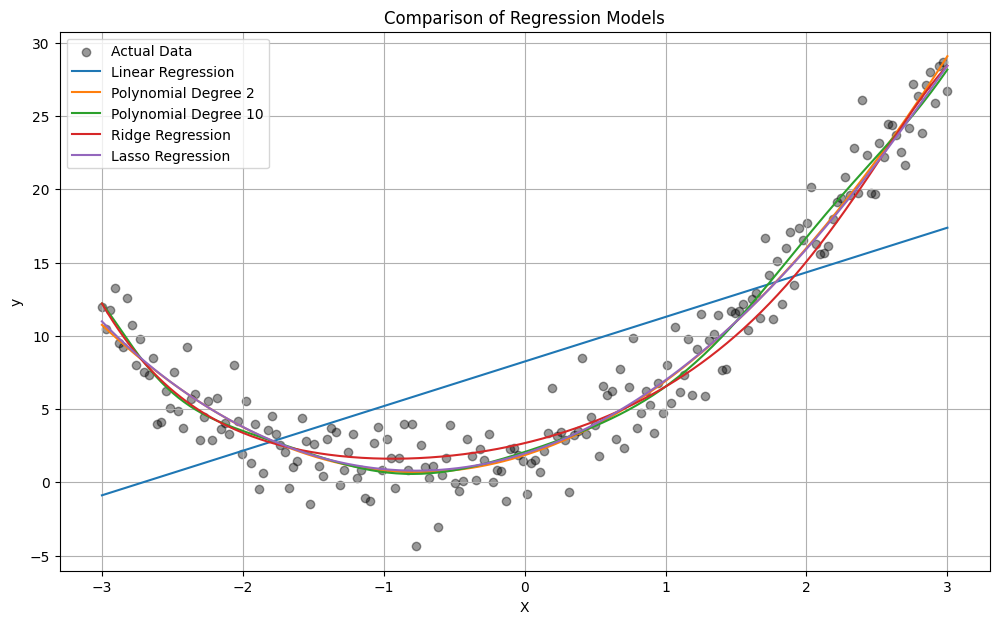

In [11]:
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.figure(figsize=(12, 7))

plt.scatter(X, y, color='black', alpha=0.4, label='Actual Data')

plt.plot(
    X_plot, linear_model.predict(X_plot),
    label='Linear Regression'
)

plt.plot(
    X_plot, poly2_model.predict(X_plot),
    label='Polynomial Degree 2'
)

plt.plot(
    X_plot, poly10_model.predict(X_plot),
    label='Polynomial Degree 10'
)

plt.plot(
    X_plot, ridge_model.predict(X_plot),
    label='Ridge Regression'
)

plt.plot(
    X_plot, lasso_model.predict(X_plot),
    label='Lasso Regression'
)

plt.title('Comparison of Regression Models')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

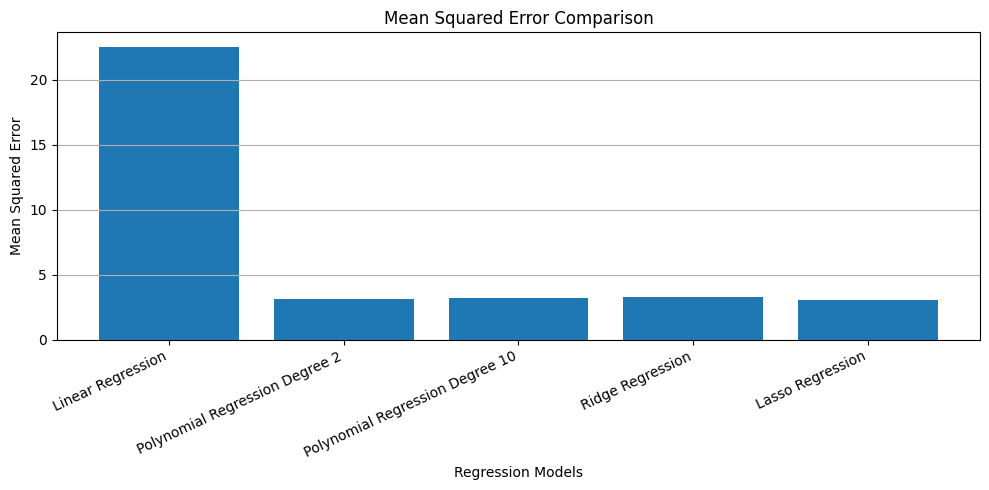

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(results['Model'], results['MSE'])

plt.title('Mean Squared Error Comparison')
plt.xlabel('Regression Models')
plt.ylabel('Mean Squared Error')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [13]:
best_model = results.loc[results['MSE'].idxmin()]

print("Best Model:", best_model['Model'])
print("Lowest Test MSE:", round(best_model['MSE'], 4))
print("RMSE:", round(best_model['RMSE'], 4))
print("R2 Score:", round(best_model['R2 Score'], 4))

Best Model: Lasso Regression
Lowest Test MSE: 3.0665
RMSE: 1.7512
R2 Score: 0.9339


In this assignment, different regression models were implemented and evaluated using a synthetic nonlinear dataset. Linear Regression was compared with Polynomial Regression of degrees 2 and 10. The results demonstrated how model complexity affects prediction performance. Ridge and Lasso regularization were applied to control model complexity and reduce overfitting. The models were evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score. The best-performing model was identified by comparing the test MSE values.